# Introduction to AI — Advanced Examples

**Notebook status:** execution below is saved from a local run. Python 3.13.14; deterministic, synthetic examples; no API credentials or external services.

## Section A — Introduction

Examine score thresholds, error costs, uncertainty, and human authorization boundaries.

**Prerequisites:** Python 3.11+, basic values and function calls. Install notebook support with `python -m pip install -e ".[notebooks]"`. **Objectives:** trace the code, explain its output, identify limitations, and suggest a real-world safety boundary. Full theory: [lesson notes](../lessons/01_introduction_to_artificial_intelligence.md).

In [1]:
import sys
import matplotlib

print(f"Python {sys.version.split()[0]} | matplotlib {matplotlib.__version__}")

Python 3.13.14 | matplotlib 3.10.8


This environment cell records the actual interpreter and plotting-library versions used for this notebook execution. Minimum compatible dependency versions are documented in the course `pyproject.toml`.

## Section B — Beginner explanation

A prediction is an output, not an action. A threshold converts a score into a decision. A score is not automatically a calibrated probability.

The code cells are runnable Python. Explanations before and after each cell distinguish the expected behavior from the actual output saved by this execution.

## Section C — First Python example

Read the inputs and operations before running. The output below is captured from actual execution.

In [2]:
scores = {"window_A": 0.12, "window_B": 0.83, "window_C": 0.56}
threshold = 0.60
for window, score in scores.items():
    decision = "review" if score >= threshold else "no alert"
    print(f"{window}: score={score:.2f}, decision={decision}")

window_A: score=0.12, decision=no alert
window_B: score=0.83, decision=review
window_C: score=0.56, decision=no alert


**Line-by-line walkthrough:** The dictionary stores illustrative scores by ID. The cutoff defines the operating rule. The loop formats each decision. Values are hand-set and are not model probabilities.

The output immediately above is actual saved execution output. It occurs because the code uses the displayed deterministic input.

## Section D — Intermediate examples

This example adds a more realistic data structure or evaluation step. Inputs are documented in the code.

In [3]:
actual, predicted = [1, 1, 0, 0, 0], [1, 0, 0, 0, 0]
tp = sum(a == p == 1 for a, p in zip(actual, predicted))
fn = sum(a == 1 and p == 0 for a, p in zip(actual, predicted))
fp = sum(a == 0 and p == 1 for a, p in zip(actual, predicted))
tn = sum(a == p == 0 for a, p in zip(actual, predicted))
print({"TP": tp, "FN": fn, "FP": fp, "TN": tn})
print(f"recall={tp/(tp+fn):.1%}; accuracy={(tp+tn)/len(actual):.1%}")

{'TP': 1, 'FN': 1, 'FP': 0, 'TN': 3}
recall=50.0%; accuracy=80.0%


This cell's output is the result of the displayed computation. New Python operations are explained in the code and can be inspected interactively.

## Section E — Advanced examples

This example adds an edge case, metric, or validation concern. Consider both computational behavior and decision consequences.

In [4]:
def recommend(score, threshold, approved=False):
    if not 0 <= score <= 1:
        raise ValueError("score must be between 0 and 1")
    if score < threshold:
        return "no recommendation"
    return "approved next step" if approved else "human review required"

print(recommend(0.9, 0.6))
print(recommend(0.9, 0.6, approved=True))

human review required
approved next step


Interpret each result in the context of the toy data; do not generalize the score to real deployments.

## Section F — Real-world applications

Example application: synthetic network engineering telemetry and read-only triage. The same principles apply to AI, data science, cloud monitoring, automation, and production software.

In [5]:
observed = [10, 11, 12, 13, 14, 50]  # synthetic time series
baseline = max(observed[:4])
print("baseline from earlier data:", baseline)
print("future deviations:", [value - baseline for value in observed[4:]])

baseline from earlier data: 13
future deviations: [1, 37]


No live network is contacted. Any production system needs data provenance, permissions, observability, human review, and a rollback/disable plan.

## Section G — Visualization

The chart below is rendered and embedded in this notebook's saved outputs. It uses the small synthetic demonstration data.

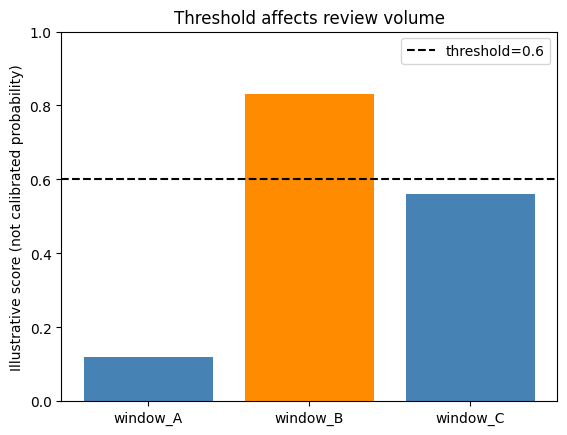

In [6]:
import matplotlib.pyplot as plt
plt.bar(list(scores), list(scores.values()), color=["steelblue" if s < threshold else "darkorange" for s in scores.values()])
plt.axhline(threshold, color="black", linestyle="--", label=f"threshold={threshold}")
plt.ylim(0, 1)
plt.ylabel("Illustrative score (not calibrated probability)")
plt.title("Threshold affects review volume")
plt.legend()
plt.show()

The figure supports visual intuition only; it is not validation evidence.

## Section H — Debugging and common mistakes

The following code intentionally reaches an invalid-input path but catches the exception, leaving an inspectable message rather than an unhandled notebook error.

In [7]:
try:
    recommend(1.2, 0.6)
except ValueError as error:
    print("Caught invalid score:", error)
print("Valid score:", recommend(0.9, 0.6))

Caught invalid score: score must be between 0 and 1
Valid score: human review required


Reject malformed input explicitly; never substitute a success-shaped prediction or silently perform an operational action.

## Section I — Exercises

1. Vary the cutoff and record review volume. 2. Create a rare-event case with high accuracy but zero recall. 3. Design an approval gate the model cannot override.

Attempt these before using the separate `07_Exercise_Solutions.ipynb`.

## Section J — Summary and knowledge check

Thresholds encode tradeoffs; safe actions require controls beyond a classifier. Explain how you would set a threshold without tuning on the test set.

**Review:** What are the input, output, assumptions, failure mode, and safe fallback? Continue with the full theory notes and then AI problem formulation: goals, state, actions, constraints, costs, and success criteria.